# Phase 08 — Baseline Infrastructure Validation (CLEAN-v3, Part 1A)

**Phase ID:** `phase_08_baseline_infrastructure`
**Part:** 1A — Clean-v3 Data / Target / Device / Reproducibility Foundation
**Model:** Gemini 3.8 Flash Medium
**Project Root:** `D:\Softfors\jup` · **Kernel:** `jup-venv`

**Active manifest:** `phase4_v3` · **Frozen taxonomy:** `kub_size_clean_v3_v1`

> This notebook **builds and validates infrastructure only**. No baseline training,
> no scientific performance claims, and no TEST content access.

## 2. Scientific / Engineering Objective

Establish and verify the clean-v3 engineering foundation on which Phase 09 baseline
training will run:

- the binary target contract (`mask > 0`)
- image-mode / input-channel behaviour
- the spatial transform contract and image–mask alignment
- a manifest-backed, TEST-locked loader
- reproducibility, metric, checkpoint, AMP and device plumbing
- frozen size-taxonomy integration

Production functionality lives under `src/`; this notebook imports and audits it.

## 3. Governance

| Rule | Value |
|---|---|
| Active manifest | `phase4_v3` (explicitly validated) |
| TEST | metadata only — **0** image/mask reads |
| TEST visualizations | **0** |
| TEST metrics | **0** |
| Baseline training | **NONE** |
| Scientific performance claims | **NONE** |
| Phase 09 | **NOT started** |
| Architecture / loss / optimizer changes | **NONE** |
| Hyperparameter tuning | **NONE** |

No scientifically material default is chosen here. Where a value is required, it is
stated explicitly or left as a labelled placeholder.

In [1]:
import json, sys, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use('Agg')
from IPython.display import Image as IPImage, display

PROJECT_ROOT = Path(r'D:\Softfors\jup')
CODE_DIR = PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_08_baseline_infrastructure' / 'code'
TABLES = PROJECT_ROOT / 'reports' / 'tables'
AUDITS = PROJECT_ROOT / 'reports' / 'audits'
FIGDIR = PROJECT_ROOT / 'reports' / 'figures' / 'phase08_baseline_infrastructure'
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(CODE_DIR))
import phase08_infrastructure_audit as p8

from src.utils.targets import binarize_mask, foreground_label_signature, is_binary
from src.utils import device as dev
from src.utils import config as cfgmod
from src.data.kub_dataset import KUBDataset
from src.data.transforms import SegmentationTransform
from src.data.loaders import create_loader
from src.metrics.segmentation import binary_metrics
from src.metrics.object_metrics import object_metrics
from src.analysis import kub_object_size as kos

print('python :', sys.version.split()[0])
print('torch  :', torch.__version__)
print('manifest:', p8.MANIFEST_VERSION, '| taxonomy:', p8.TAXONOMY_ID)

python : 3.11.9
torch  : 2.6.0+cu124
manifest: phase4_v3 | taxonomy: kub_size_clean_v3_v1


## 4. Environment + CUDA

In [2]:
env = dev.device_report()
for k, v in env.items():
    print(f'{k:26s}: {v}')
print()
print('get_device(require_cuda=True) ->', dev.get_device(require_cuda=True))
print('AMP supported                ->', dev.amp_supported())
print()
print('CUDA is REQUIRED for canonical runs; CPU fallback is never silent.')

cuda_available            : True
cuda_device_count         : 1
cuda_device               : NVIDIA GeForce RTX 3060 Ti
pytorch_version           : 2.6.0+cu124
cuda_runtime_version      : 12.4
cudnn_version             : 90100
cuda_capability           : [8, 6]
canonical_requires_cuda   : True

get_device(require_cuda=True) -> cuda:0
AMP supported                -> True

CUDA is REQUIRED for canonical runs; CPU fallback is never silent.


## 5. Active Manifest Verification

`phase4_v3` is validated explicitly through the manifest guard. Root
`manifests/*.csv` (phase4_v2) is historical provenance and is not used.

In [3]:
manifests = p8.verify_manifests()
print('guard ok            :', manifests['guard_ok'])
print('guard files         :', manifests['guard_files'])
print('KUB TRAIN cases     :', manifests['kub_train_cases'])
print('KUB VAL cases       :', manifests['kub_val_cases'])
print('TRAIN patients      :', manifests['train_patients'])
print('VAL patients        :', manifests['val_patients'])
print('patient overlap     :', manifests['patient_overlap'])
print('TEST metadata rows  :', manifests['test_metadata_rows'], '(metadata only, never decoded)')
assert manifests['guard_ok'] and manifests['counts_ok']
print()
print('HARD GATE PASS: phase4_v3 validated, 1978/280, overlap 0')
train_df = pd.read_csv(p8.TRAIN_MANIFEST)

guard ok            : True
guard files         : ['all_paired', 'duplicate_groups', 'grouping_provenance', 'quarantined', 'test', 'train', 'val']
KUB TRAIN cases     : 1978
KUB VAL cases       : 280
TRAIN patients      : 318
VAL patients        : 111
patient overlap     : 0
TEST metadata rows  : 558 (metadata only, never decoded)

HARD GATE PASS: phase4_v3 validated, 1978/280, overlap 0


## 6. Target Semantic Contract

**BACKGROUND = `mask == 0`; FOREGROUND = `mask > 0`.** Native KUB masks use a
heterogeneous nonzero label vocabulary; `mask == 1` must never be assumed.

In [4]:
target = p8.audit_target_contract(train_df)
print('foreground rule          :', target['foreground_rule'])
print('samples audited          :', target['samples_audited'])
print('raw label union          :', target['raw_label_union'])
print('non-1 foreground labels  :', target['non_one_foreground_labels'])
print('binarize equivalence fail:', target['binarize_equivalence_failures'])
print('non-binary after binarize:', target['non_binary_after_binarize'])
print()
print('observed raw label signatures:')
for k, v in target['label_signatures'].items():
    print(f'   {k:14s} {v:5d} samples')

foreground rule          : mask > 0
samples audited          : 360
raw label union          : [0, 1, 2, 3, 255]
non-1 foreground labels  : [2, 3, 255]
binarize equivalence fail: 0
non-binary after binarize: 0

observed raw label signatures:
   0|1              120 samples
   0|1|2              3 samples
   0|2              117 samples
   0|255             23 samples
   0|3               97 samples


In [5]:
# direct demonstration on synthetic masks
for label in (1, 2, 3, 255):
    m = np.zeros((6, 6), dtype=np.uint8); m[2, 2] = label
    out = binarize_mask(m)
    print(f'label {label:3d} -> foreground={int(out.sum())} binary={is_binary(out)}')

label   1 -> foreground=1 binary=True
label   2 -> foreground=1 binary=True
label   3 -> foreground=1 binary=True
label 255 -> foreground=1 binary=True


## 7. Image-Mode / Channel Audit

FULL_FIELD images are RGB; ROI crops are single-channel `L`. The historical
pipeline converts both to a **1-channel** tensor and that convention is preserved.

In [6]:
image_modes = p8.audit_image_modes(train_df)
print('source mode counts:', image_modes['source_mode_counts'])
print()
for c in image_modes['channel_checks']:
    print(f"  source {c['source_mode']:4s} -> tensor {c['tensor_shape']} ({c['tensor_channels']} channel)")
print()
print('input channel convention:', image_modes['input_channel_convention'])
print(image_modes['convention_note'])

source mode counts: {"('FULL_FIELD', 'RGB')": 120}

  source L    -> tensor (1, 256, 256) (1 channel)
  source RGB  -> tensor (1, 256, 256) (1 channel)

input channel convention: 1
KUBDataset calls Image.convert("L") then unsqueeze(0), so both RGB (FULL_FIELD) and L (ROI) images become a 1-channel tensor. This is the historical convention and is preserved.


## 8. Transform Contract

Aspect-preserving resize + centre pad, `scale = min(size/w, size/h)`, bilinear
image / **nearest** mask. This is the documented historical preprocessing and is
not replaced by non-isotropic stretching.

In [7]:
transform_df = p8.audit_transform_contract(train_df)
p8.write_table(transform_df, 'phase08_transform_contract_audit.csv', TABLES)
display(transform_df[['target_size','source_h','source_w','actual_scale','resized_w','resized_h',
                      'pad_left','pad_top','padded_w_ok','padded_h_ok','aligned','mask_is_binary',
                      'mask_foreground_preserved']])
print()
print('all padded to target :', bool(transform_df['padded_w_ok'].all() and transform_df['padded_h_ok'].all()))
print('all image/mask aligned:', bool(transform_df['aligned'].all()))
print('all masks binary      :', bool(transform_df['mask_is_binary'].all()))
print('all FG preserved      :', bool(transform_df['mask_foreground_preserved'].all()))

,target_size,source_h,source_w,actual_scale,resized_w,resized_h,pad_left,pad_top,padded_w_ok,padded_h_ok,aligned,mask_is_binary,mask_foreground_preserved
0,256,3072,3072,0.083333,256,256,0,0,True,True,True,True,True
1,256,2880,2304,0.088889,205,256,25,0,True,True,True,True,True
2,256,80,60,3.200000,192,256,32,0,True,True,True,True,True
3,256,512,512,0.500000,256,256,0,0,True,True,True,True,True
4,512,3072,3072,0.166667,512,512,0,0,True,True,True,True,True
5,512,2880,2304,0.177778,410,512,51,0,True,True,True,True,True
6,512,80,60,6.400000,384,512,64,0,True,True,True,True,True
7,512,512,512,1.000000,512,512,0,0,True,True,True,True,True



all padded to target : True
all image/mask aligned: True
all masks binary      : True
all FG preserved      : True


## 9. Loader Construction

`KUBDataset` is manifest-backed and TEST-locked; `create_loader` builds a
seeded `DataLoader` with pinned memory and worker seeding.

In [8]:
ds = KUBDataset(p8.TRAIN_MANIFEST, 'TRAIN', target_size=256, cache_in_memory=False)
print('TRAIN dataset length:', len(ds))
loader = create_loader(ds, batch_size=4, shuffle=False, seed=42, num_workers=0, pin_memory=True)
batch = next(iter(loader))
print('batch image:', tuple(batch['image'].shape), batch['image'].dtype)
print('batch mask :', tuple(batch['mask'].shape), batch['mask'].dtype)
print('mask unique:', torch.unique(batch['mask']).tolist())
print()
try:
    KUBDataset(p8.TRAIN_MANIFEST, 'TEST')
    print('ERROR: TEST construction should have been blocked')
except Exception as e:
    print('TEST construction blocked:', type(e).__name__)

TRAIN dataset length: 1978


batch image: (4, 1, 256, 256) torch.float32
batch mask : (4, 1, 256, 256) torch.float32
mask unique: [0.0, 1.0]

TEST construction blocked: TestAccessError


## 10. Deterministic Sample Audit

Selection is deterministic and prediction-independent, stratified by
(acquisition, category) and forced to cover every observed raw label signature.

In [9]:
sel = p8.deterministic_sample_selection(train_df, n_total=16)
sample_df, _ = p8.audit_loader_samples(sel)
p8.write_table(sample_df, 'phase08_kub_v3_loader_sample_audit.csv', TABLES)
SELECTION_SHA = p8.sha256_of_strings(sample_df['sample_id'].tolist())
display(sample_df[['sample_id','category','acquisition_type','source_image_mode',
                   'raw_mask_label_signature','tensor_shape','binary_mask_unique_values',
                   'foreground_pixel_count','mask_is_binary']])
print('cases                :', len(sample_df))
print('acquisition coverage :', sample_df['acquisition_type'].value_counts().to_dict())
print('category coverage    :', sample_df['category'].value_counts().to_dict())
print('label signatures     :', sample_df['raw_mask_label_signature'].value_counts().to_dict())
print('selection SHA        :', SELECTION_SHA)

,sample_id,category,acquisition_type,source_image_mode,raw_mask_label_signature,tensor_shape,binary_mask_unique_values,foreground_pixel_count,mask_is_binary
0,00493050556465a8114f4141b84a8534,Bladder_Stone,ROI,L,0|255,"(1, 256, 256)",0|1,15981,True
1,00898dbf7b16b032ac8299d37b8fe7d4,Kidney_Stone,FULL_FIELD,RGB,0|1,"(1, 256, 256)",0|1,111,True
2,009bdd366dd0fed05413903efcf1cfbb,Kidney_Stone,ROI,L,0|255,"(1, 256, 256)",0|1,20864,True
3,029428961ddb4f21fd784454777a1524,Bladder_Stone,FULL_FIELD,RGB,0|2,"(1, 256, 256)",0|1,8,True
4,06e2583b9bfca7b611c6fcb5aea34451,Ureteric_Stone,FULL_FIELD,RGB,0|3,"(1, 256, 256)",0|1,14,True
5,3d315ea082371bc817451394dc6f9bdb,Bladder_Stone,FULL_FIELD,RGB,0|1|2,"(1, 256, 256)",0|1,106,True
6,44d22d0f30f9196446c842639cff120f,Bladder_Stone,ROI,L,0|255,"(1, 256, 256)",0|1,9813,True
7,776e8a18d67468bff36086ca4f3c9d85,Ureteric_Stone,ROI,L,0|255,"(1, 256, 256)",0|1,18593,True
8,78880b4420a45b93f20800102a825846,Bladder_Stone,ROI,L,0|255,"(1, 256, 256)",0|1,21867,True
9,7f8ff6a340fd02dcad6a058a2a36c501,Ureteric_Stone,FULL_FIELD,RGB,0|3,"(1, 256, 256)",0|1,11,True


cases                : 16
acquisition coverage : {'ROI': 8, 'FULL_FIELD': 8}
category coverage    : {'Bladder_Stone': 7, 'Kidney_Stone': 6, 'Ureteric_Stone': 3}
label signatures     : {'0|255': 8, '0|1': 3, '0|2': 2, '0|3': 2, '0|1|2': 1}
selection SHA        : c29d47a855c56a2fa3218a23b133e3380de9ee89a28790622794f874a83abc2b


## 11. Medical Visual Loader Gallery

Source image, source binary GT, transformed image, transformed binary GT, and
overlay — verifying loader/transform fidelity. ROI grayscale is rendered
faithfully. No predictions, no TEST.

In [10]:
gal = p8.loader_gallery_pages(sel, cases_per_page=4)
GAL_PATHS = []
for i, f in enumerate(gal, 1):
    gp = p8.save_fig(f, FIGDIR / f'phase08_loader_gallery_page{i:02d}.png')
    GAL_PATHS.append(gp)
print('gallery pages:', len(GAL_PATHS))

gallery pages: 4


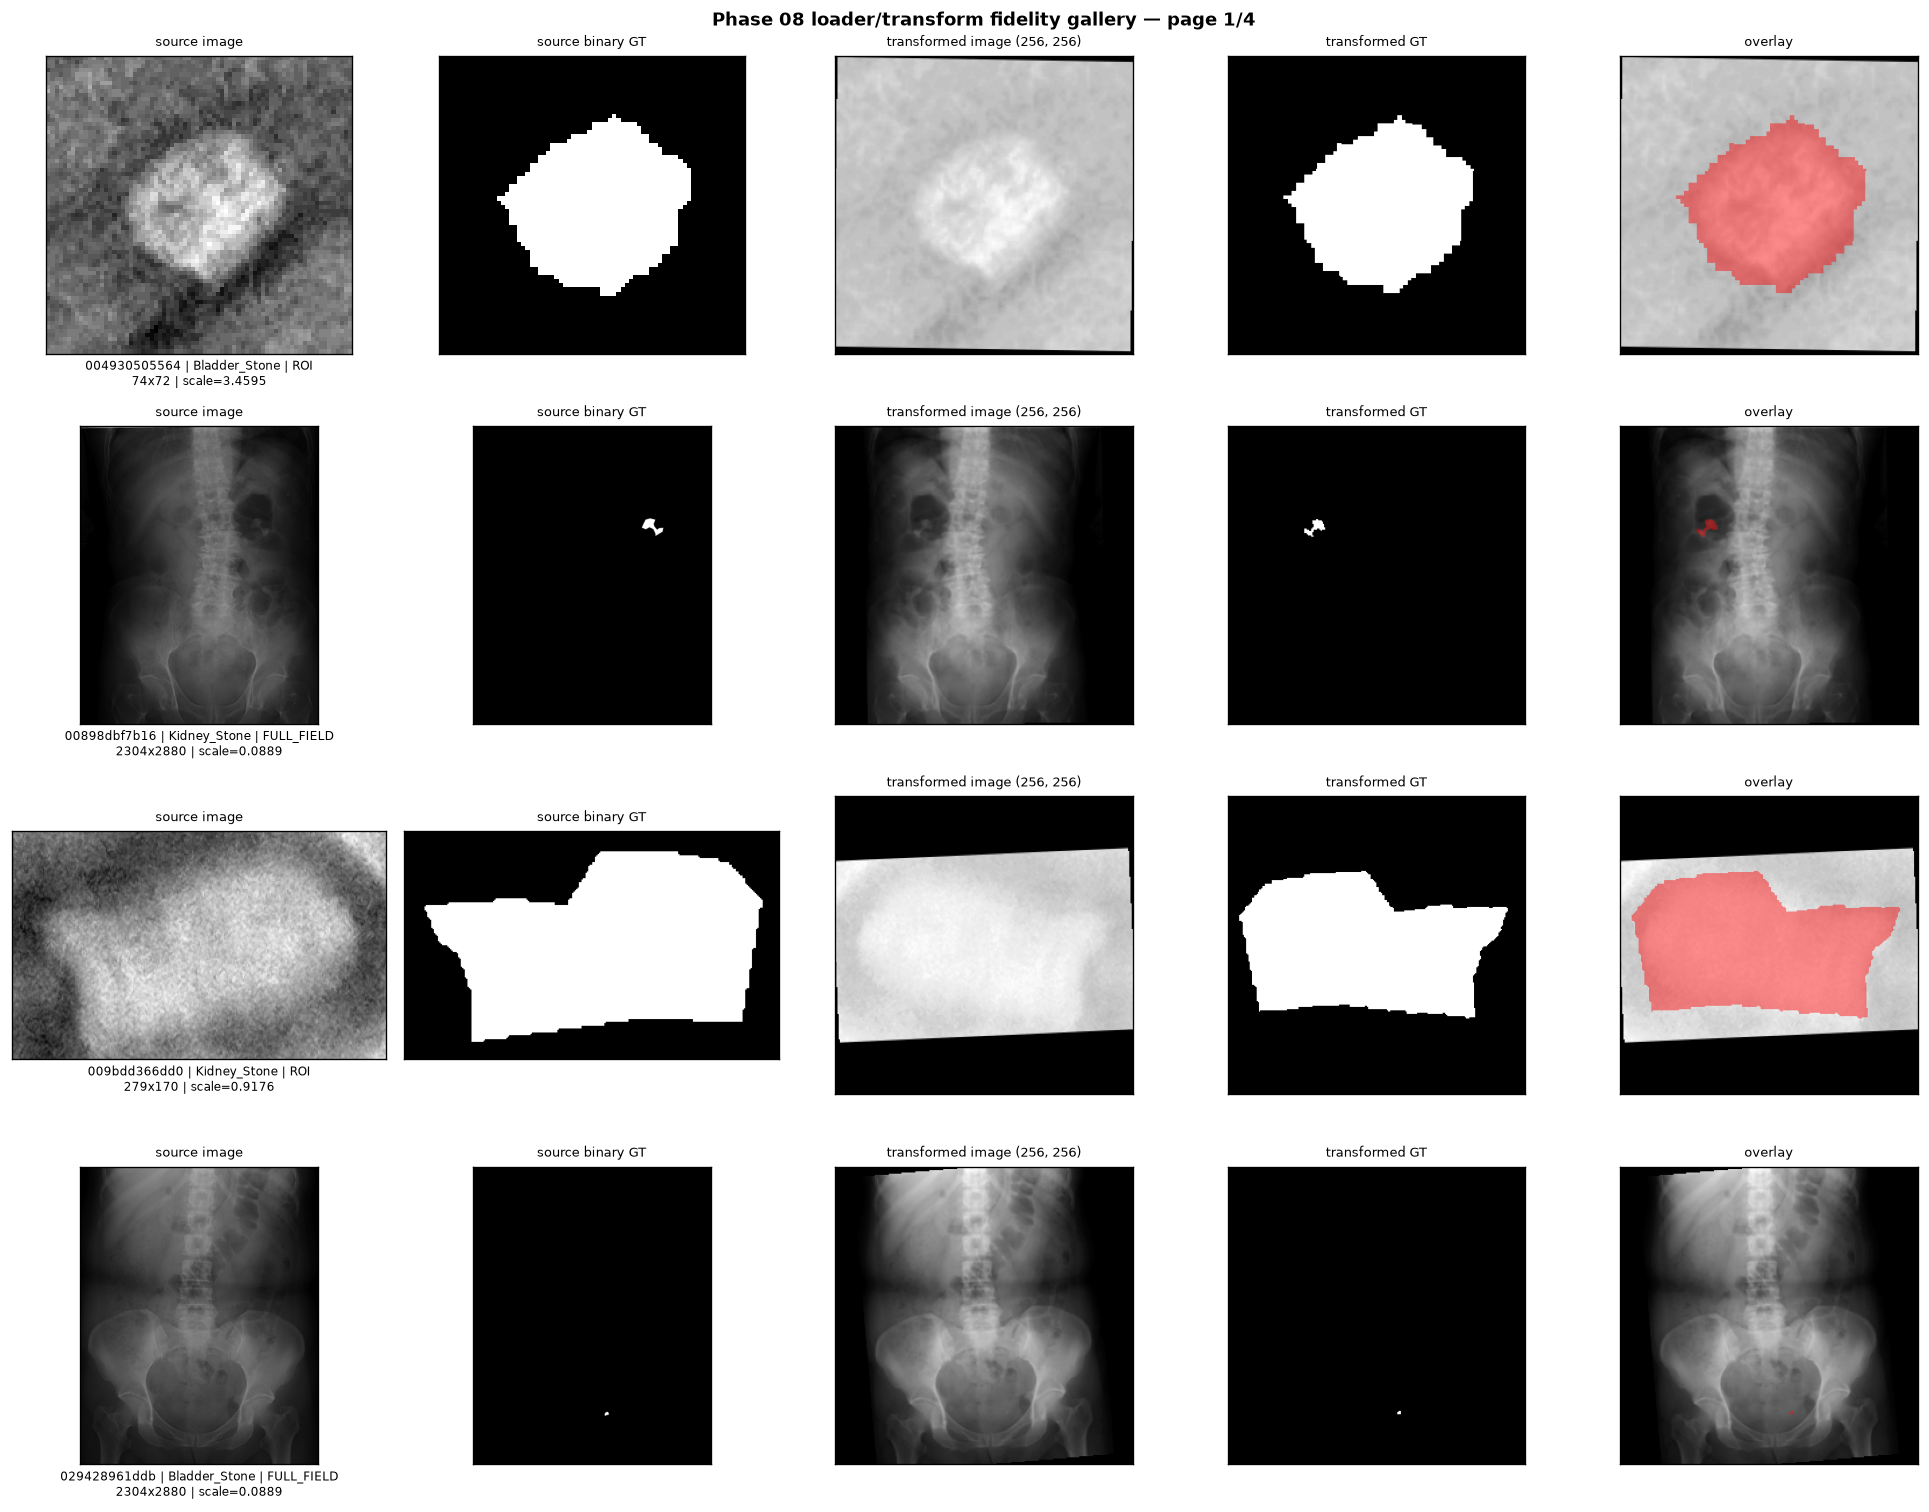

In [11]:
display(IPImage(filename=str(FIGDIR / f'phase08_loader_gallery_page01.png')))

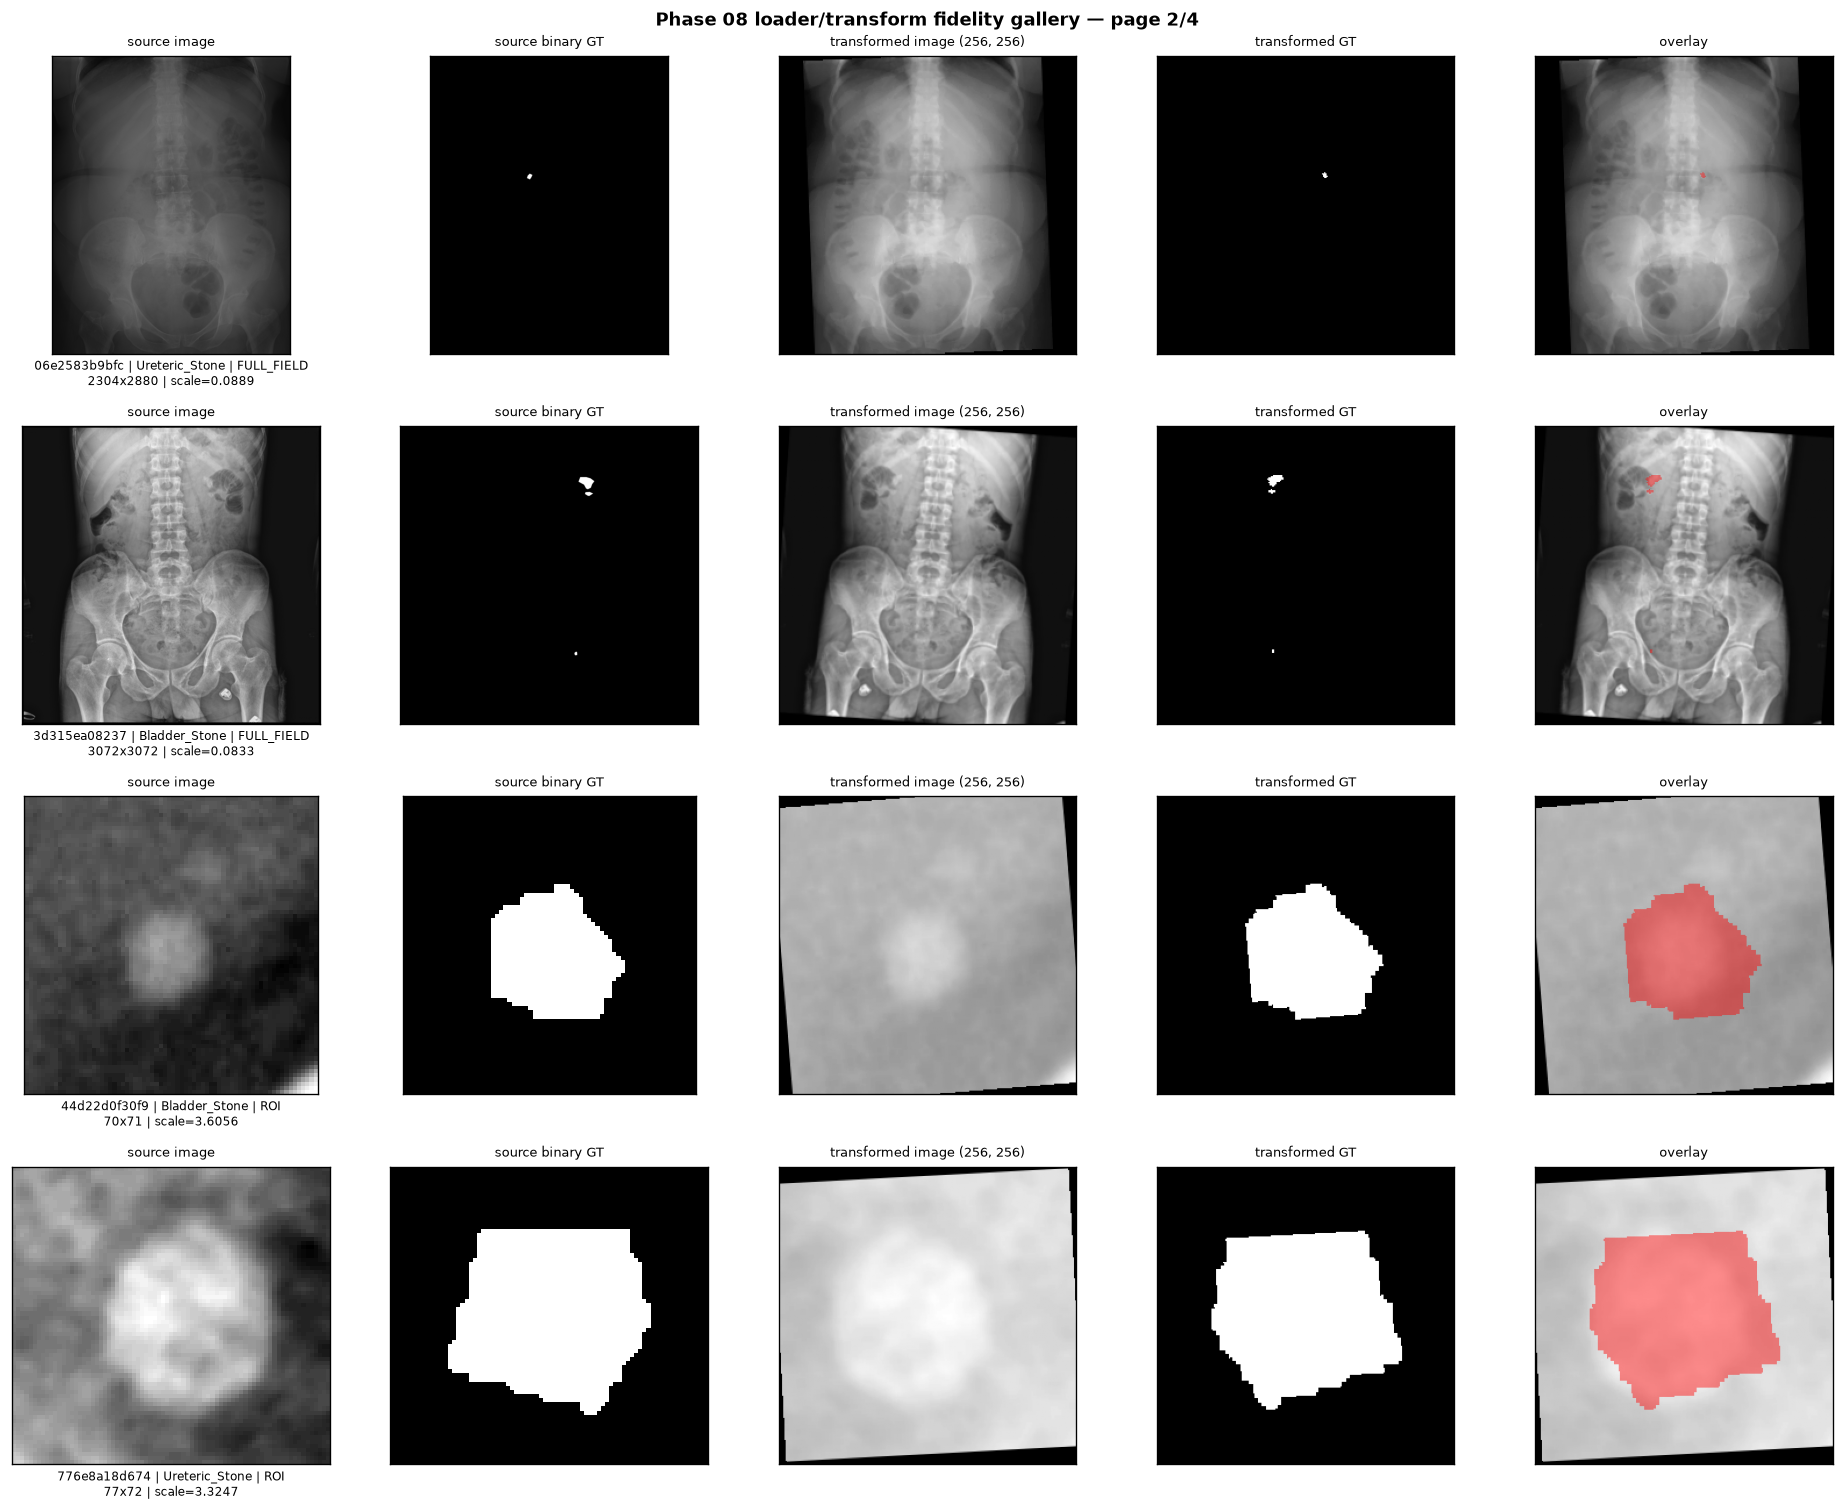

In [12]:
display(IPImage(filename=str(FIGDIR / f'phase08_loader_gallery_page02.png')))

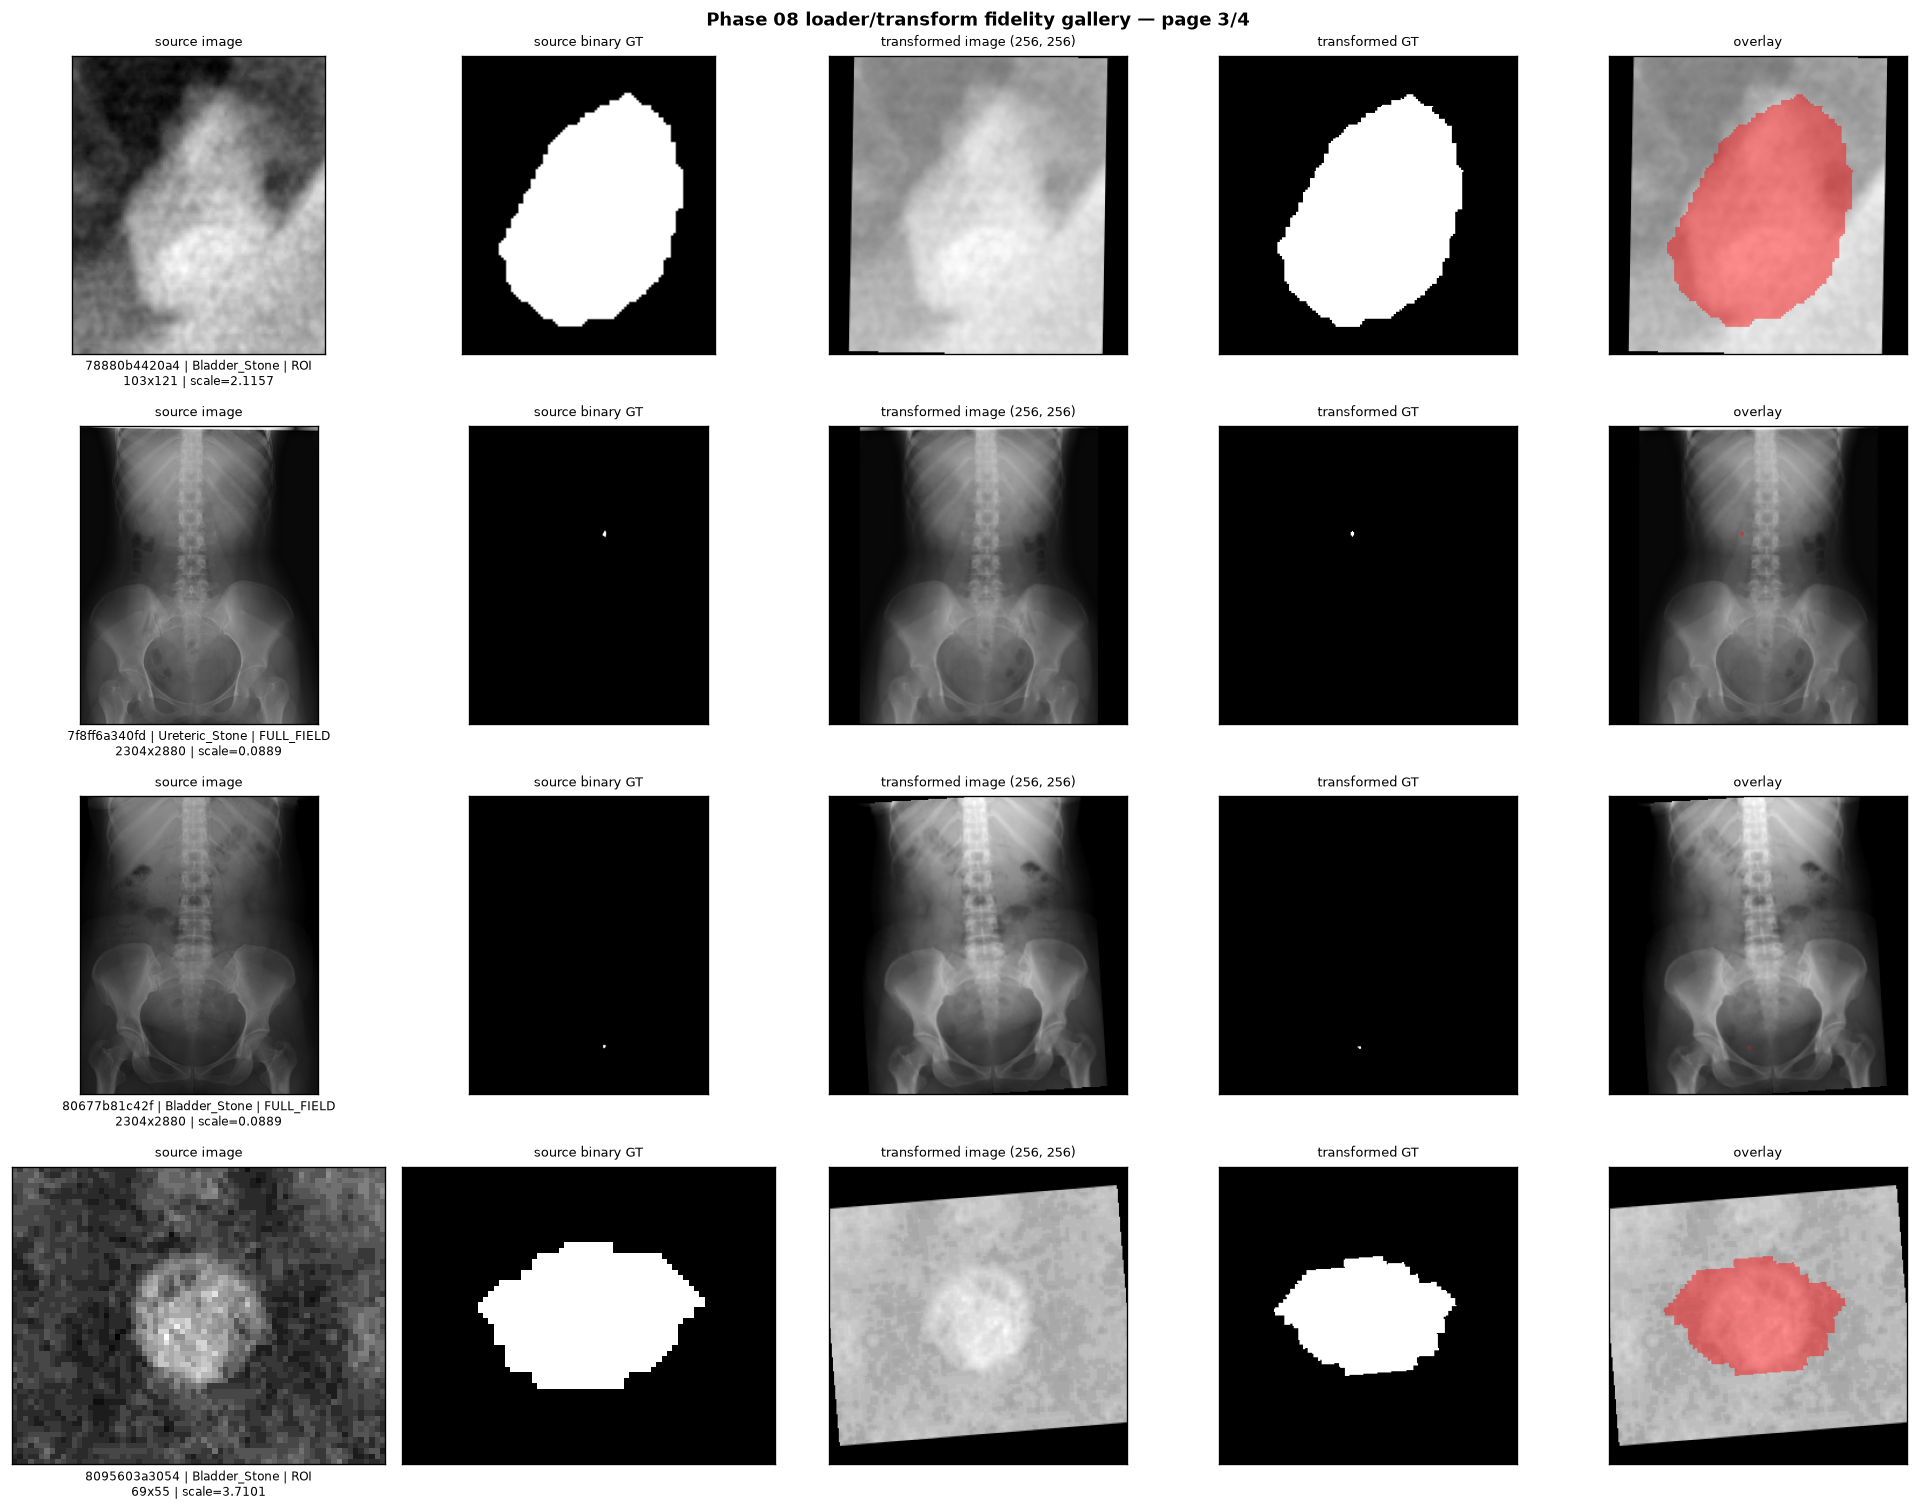

In [13]:
display(IPImage(filename=str(FIGDIR / f'phase08_loader_gallery_page03.png')))

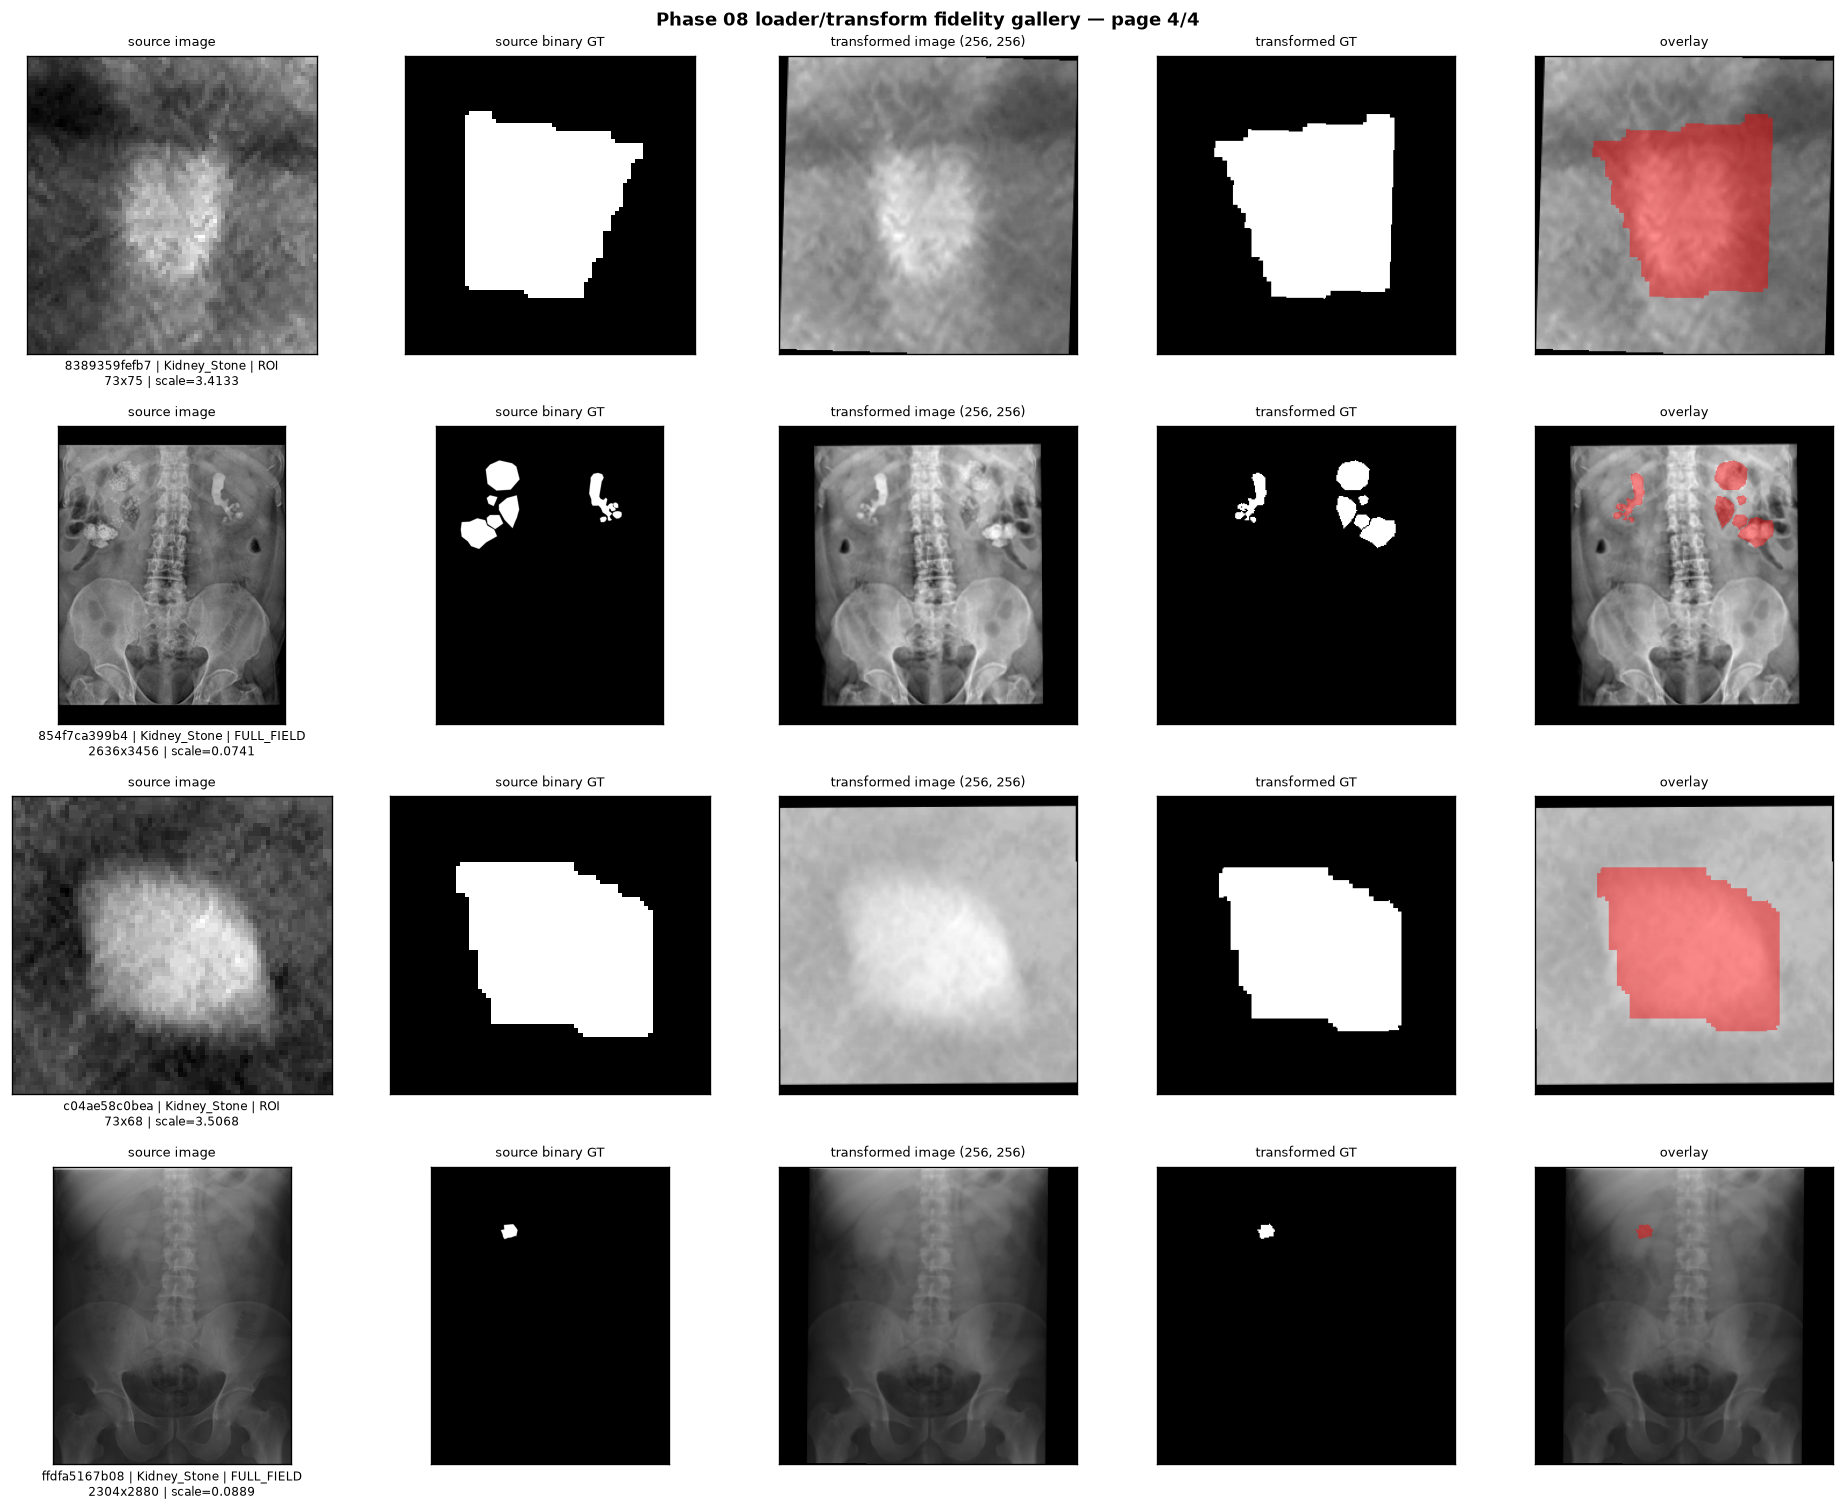

In [14]:
display(IPImage(filename=str(FIGDIR / f'phase08_loader_gallery_page04.png')))

## 12. Reproducibility / Seed Audit

Seeding covers Python, NumPy, torch CPU, CUDA, DataLoader workers, and a
deterministic generator. **Bitwise GPU determinism is NOT claimed.**

In [15]:
repro_df = p8.audit_reproducibility()
p8.write_table(repro_df, 'phase08_reproducibility_audit.csv', TABLES)
display(repro_df)
print()
print('determinism policy: cudnn.deterministic=%s, cudnn.benchmark=%s' % (
    torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark))
print('torch.use_deterministic_algorithms:', torch.are_deterministic_algorithms_enabled())
print()
print('TRAIN access is stochastic by design (augmentation); reproducibility is')
print('achieved by seeding. VAL access is deterministic.')

,check,result,detail
0,python_numpy_torch_seed,PASS,set_seed reproduces python/numpy/torch draws
1,cuda_seed,PASS,cuda.manual_seed_all reproduces CUDA draws
2,dataloader_generator,PASS,make_generator(seed) is reproducible
3,worker_seed,PASS,seed_worker produces deterministic per-worker ...
4,rng_state_roundtrip,PASS,capture/restore reproduces the torch CPU stream
5,determinism_policy,DOCUMENTED,"cudnn.deterministic=True, cudnn.benchmark=Fals..."
6,torch_deterministic_algorithms,False,not force-enabled: some CUDA ops lack determin...



determinism policy: cudnn.deterministic=True, cudnn.benchmark=False
torch.use_deterministic_algorithms: False

TRAIN access is stochastic by design (augmentation); reproducibility is
achieved by seeding. VAL access is deterministic.


## 13. Metric Contract

Dice, IoU, precision, recall (and HD95 / object recall) are centralized with
explicit threshold, epsilon and empty-mask conventions. **No metric definition is
changed or retuned here.**

In [16]:
metric_df = p8.audit_metric_contract()
p8.write_table(metric_df, 'phase08_metric_contract.csv', TABLES)
display(metric_df[['metric','module','function','version','threshold','epsilon','empty_handling']])
print()
om = object_metrics(np.zeros((8,8),bool), np.zeros((8,8),bool))
print('object_metrics connectivity:', om['connectivity'],
      '| minimum_overlap_pixels:', om['minimum_overlap_pixels'])
print('object metric convention is EXPLICIT (8-connectivity, overlap-based).')

,metric,module,function,version,threshold,epsilon,empty_handling
0,dice,src.metrics.segmentation,binary_metrics,v1,0.5,1.000000e-07,"epsilon-smoothed, defined for empty masks"
1,iou,src.metrics.segmentation,binary_metrics,v1,0.5,1.000000e-07,epsilon-smoothed
2,precision,src.metrics.segmentation,binary_metrics,v1,0.5,1.000000e-07,epsilon-smoothed
3,recall,src.metrics.segmentation,binary_metrics,v1,0.5,1.000000e-07,epsilon-smoothed
4,hd95,src.metrics.segmentation,hd95,v1,NaN,NaN,explicit hd95_valid flag; NaN or supplied pena...
5,object_recall,src.metrics.object_metrics,object_metrics,phase14_authoritative,NaN,NaN,NaN recall when no GT components



object_metrics connectivity: 8 | minimum_overlap_pixels: 1
object metric convention is EXPLICIT (8-connectivity, overlap-based).


## 14. Frozen Size-Taxonomy Integration

Object-level metadata loads the frozen taxonomy through the versioned API. ROI
components are never primary-binned.

In [17]:
taxonomy = p8.audit_taxonomy_integration(train_df)
print('taxonomy_id :', taxonomy['taxonomy_id'])
print('thresholds  :', taxonomy['thresholds'])
print('FF strata (sample):', taxonomy['full_field_strata_sample'])
print('ROI handling:', taxonomy['roi_handling'])
print('ROI-specific taxonomy created:', taxonomy['roi_specific_taxonomy_created'])
print()
print(taxonomy['note'])

taxonomy_id : kub_size_clean_v3_v1
thresholds  : {'Q25': 0.0001497998649691358, 'Q50': 0.0003401438395182292, 'Q75': 0.0008279682677469136}
FF strata (sample): {'MEDIUM': 9, 'TINY': 79, 'LARGE': 1, 'SMALL': 15}
ROI handling: ROI_NOT_PRIMARY_BINNED
ROI-specific taxonomy created: False

Object-level metadata uses 8-connectivity; training masks remain ordinary binary masks.


## 15. AMP Foundation

CUDA AMP plumbing compatible with PyTorch 2.6: `torch.amp.autocast('cuda')` and
`torch.amp.GradScaler('cuda')`, with scaler-state save/restore.

In [18]:
print('AMP supported:', dev.amp_supported())
scaler = dev.make_grad_scaler(enabled=True)
st = scaler.state_dict()
scaler2 = dev.make_grad_scaler(enabled=True)
scaler2.load_state_dict(st)
print('GradScaler state keys:', sorted(st.keys()))
print('GradScaler state round-trip: OK')

AMP supported: True
GradScaler state keys: ['_growth_tracker', 'backoff_factor', 'growth_factor', 'growth_interval', 'scale']
GradScaler state round-trip: OK


## 16. Checkpoint / Resume Contract

Checkpoints store model/optimizer/scheduler/scaler state, epoch, best metric,
experiment ID, seed, manifest version, taxonomy ID, config and RNG state. Resume
restores the same experiment ID — no autonomous new IDs for retries.

In [19]:
with tempfile.TemporaryDirectory() as tmp:
    ckpt_df = p8.audit_checkpoint_contract(Path(tmp))
p8.write_table(ckpt_df, 'phase08_checkpoint_contract.csv', TABLES)
display(ckpt_df)

,item,supported,detail
0,model_state,True,written by save_training_checkpoint
1,optimizer_state,True,written by save_training_checkpoint
2,scheduler_state,True,written by save_training_checkpoint
3,grad_scaler_state,True,written by save_training_checkpoint
4,epoch,True,written by save_training_checkpoint
5,best_validation_score,True,written by save_training_checkpoint
6,experiment_id,True,written by save_training_checkpoint
7,seed,True,written by save_training_checkpoint
8,manifest_version,True,written by save_training_checkpoint
9,taxonomy_id,True,written by save_training_checkpoint


## 17. Minimal CUDA Smoke Step

**INFRASTRUCTURE_TEST_ONLY.** A tiny number of TRAIN batches through an existing
baseline model verify CUDA tensors, forward, binary target shape, loss, backward,
optimizer step, AMP, GradScaler, finiteness and GPU memory. This is **not**
baseline training and produces **no scientific result**.

In [20]:
smoke = p8.cuda_smoke_test(sel)
for k, v in smoke.items():
    print(f'{k:24s}: {v}')
print()
print('No epochs run. No architecture comparison. No scientific claim.')

performed               : True
label                   : INFRASTRUCTURE_TEST_ONLY
device                  : cuda:0
device_name             : NVIDIA GeForce RTX 3060 Ti
batches                 : 2
batch_size              : 2
input_shape             : (2, 1, 256, 256)
target_shape            : (2, 1, 256, 256)
target_is_binary        : True
losses_finite           : True
amp_enabled             : True
grad_scaler_used        : True
peak_memory_mb          : 53.28
scientific_claim        : NONE
note                    : Model is an existing baseline used only as an engineering smoke vehicle.

No epochs run. No architecture comparison. No scientific claim.


## 18. Unit-Test Summary

In [21]:
import subprocess
proc = subprocess.run([str(PROJECT_ROOT / '.venv' / 'Scripts' / 'python.exe'), '-m', 'pytest',
                       'tests/test_phase08_infrastructure.py', '-q', '--no-header'],
                      cwd=str(PROJECT_ROOT), capture_output=True, text=True)
print((proc.stdout or proc.stderr).strip().splitlines()[-1])

49 passed in 5.16s


## 19. Limitations

- Infrastructure validation only: no training, no inference, no performance claims.
- The CUDA smoke step is an engineering check, not a scientific result.
- Bitwise GPU determinism is **not** guaranteed or claimed.
- The frozen taxonomy is applied to FULL_FIELD object metadata only; ROI is
  deliberately not primary-binned.
- Three pre-existing test failures/hangs in unrelated historical modules
  (`test_predicted_roi`, `test_kub_localizer`, `test_phase14_part1`) are noted and
  left untouched — they are outside this phase's scope.

## 20. Phase-08 Part-1A Conclusion

The clean-v3 engineering foundation is validated: `phase4_v3` is explicitly
guarded, the `mask > 0` target contract is enforced and tested against the real
heterogeneous label vocabulary, image-mode handling is correct, the transform
geometry and nearest-neighbour mask handling are verified, the CUDA-required
device path works, reproducibility/metric/checkpoint/AMP plumbing is exercised, and
the frozen taxonomy integrates through a versioned API. No TEST content was
accessed and no baseline training was started.

## 21. Why Phase-08 Part 1B Follows

Part 1A proves the plumbing. Part 1B can then build the remaining baseline
infrastructure — the training loop wiring, validation-accumulation and early-stopping
contracts, and the experiment-configuration defaults — still without starting
Phase-09 scientific training, which requires separate authorization.

## 22. Artifact Hashes

In [22]:
ledger = {
    'manifest_version': p8.MANIFEST_VERSION,
    'taxonomy_id': p8.TAXONOMY_ID,
    'manifest_hashes': manifests['manifest_hashes'],
    'loader_selection_sha': SELECTION_SHA,
    'environment': env,
    'cuda_smoke_performed': smoke.get('performed'),
    'test_content_reads': 0,
    'full_training_performed': False,
    'phase09_started': False,
}
print(json.dumps(ledger, indent=2, default=str))
print()
reg = p8.final_table_registry(TABLES)
display(reg)
print('TABLE COUNT:', int(reg['exists'].sum()))

{
  "manifest_version": "phase4_v3",
  "taxonomy_id": "kub_size_clean_v3_v1",
  "manifest_hashes": {
    "train": "28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21db7cd8c066055826ed6",
    "val": "082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315",
    "test": "9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727",
    "quarantined": "a4ec1a8c46692f3c2d55d03c73569ce7b44aeeef734abd41e31bf5bf3e60059c"
  },
  "loader_selection_sha": "c29d47a855c56a2fa3218a23b133e3380de9ee89a28790622794f874a83abc2b",
  "environment": {
    "cuda_available": true,
    "cuda_device_count": 1,
    "cuda_device": "NVIDIA GeForce RTX 3060 Ti",
    "pytorch_version": "2.6.0+cu124",
    "cuda_runtime_version": "12.4",
    "cudnn_version": 90100,
    "cuda_capability": [
      8,
      6
    ],
    "canonical_requires_cuda": true
  },
  "cuda_smoke_performed": true,
  "test_content_reads": 0,
  "full_training_performed": false,
  "phase09_started": false
}



,table,exists,bytes,sha256
0,phase08_kub_v3_loader_sample_audit.csv,True,2907,5da08756a67a8666c12095cda8fdd51afc4989bf0bf79f...
1,phase08_transform_contract_audit.csv,True,1033,8ebdfb532f6ec3c45f0dcd55a42594824468ca48063498...
2,phase08_metric_contract.csv,True,1283,030210f16d841591c652d7eff2f228c8beab2221845591...
3,phase08_reproducibility_audit.csv,True,584,725ddce8fccef503291b5c7e48a6d2482de38500a27853...
4,phase08_checkpoint_contract.csv,True,952,a7519387ff3f2c3bb36c93f830da221312c306dac60db1...


TABLE COUNT: 5


In [23]:
print('=' * 62)
print('PHASE 08 PART 1A — FINAL STATUS')
print('=' * 62)
print('ACTIVE MANIFEST        :', p8.MANIFEST_VERSION)
print('FROZEN TAXONOMY        :', p8.TAXONOMY_ID)
print('FOREGROUND RULE        : mask > 0')
print('INPUT CHANNELS         : 1')
print('TEST CONTENT READS     : 0')
print('FULL TRAINING PERFORMED: NO')
print('SCIENTIFIC CLAIMS      : NONE')
print('PHASE 09 STARTED       : NO')
print('=' * 62)

PHASE 08 PART 1A — FINAL STATUS
ACTIVE MANIFEST        : phase4_v3
FROZEN TAXONOMY        : kub_size_clean_v3_v1
FOREGROUND RULE        : mask > 0
INPUT CHANNELS         : 1
TEST CONTENT READS     : 0
FULL TRAINING PERFORMED: NO
SCIENTIFIC CLAIMS      : NONE
PHASE 09 STARTED       : NO
